<a href="https://colab.research.google.com/github/Hamgo272/doppler-tracking/blob/main/trackerv1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

install packages needed here (use pip)

In [ ]:
%pip install matplot librosa numpy

trumpet   	Mihai Sorohan - Trumpet loop
--------------------------------------------------------------------
Part of "Jazz Trumpet Loops Pack in F 90 bpm" by Mihai Sorohan

All parts in this pack are in F, mostly Blues and Dorian scale and all are in stereo acidized .wav format, 16 bit, 44.1 khz sample rate, 90 bpm. 

From Freesound.org https://freesound.org/s/77711/

CC-BY https://creativecommons.org/licenses/by/3.0/

stft shape=(1025, 230)


/tmp/ipykernel_7960/2920746532.py:62: UserWarning: Trying to display complex-valued input. Showing magnitude instead.
  librosa.display.specshow(stft, x_axis="time", y_axis="hz", vscale="dB")


AttributeError: QuadMesh.set() got an unexpected keyword argument 'vscale'

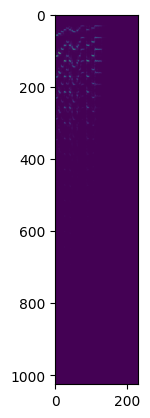

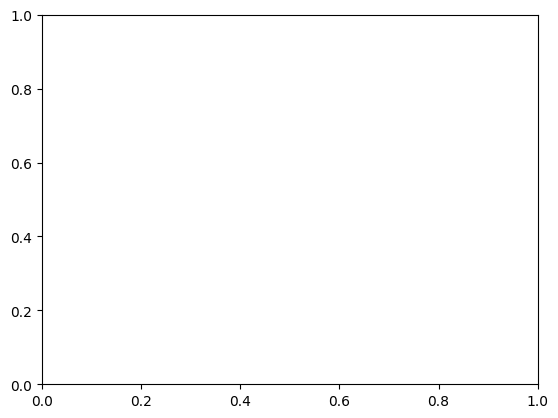

In [ ]:


# %%
# .. _tutorial-display-spectrogram:
#
# Spectrograms
# ------------
# The :ref:`earlier sections <tutorial-intro-frequency>` of this tutorial demonstrate basic
# usage of the short-time Fourier transform (STFT), which can be useful for visualizing how
# the frequency content of a signal changes over time.
# This kind of visualization is known as a **spectrogram**, and you may have encountered
# this idea before.
# While spectrograms can be interpreted as *images* and displayed using `matplotlib`'s
# general-purpose image display functions (e.g. `matplotlib.pyplot.imshow`), there are several
# subtleties that can arise and it takes a bit of effort to get it right.
#
# As an example, let's create an STFT and display it using `imshow` directly.
# We'll first set up our imports and load an example file.

# sphinx_gallery_thumbnail_number = 6
import numpy as np
import librosa
import matplotlib.pyplot as plt
from IPython.display import HTML

y, sr = librosa.load(librosa.example("trumpet"))
HTML(librosa.util.example_info("trumpet"))

# %%
# Now we can compute the STFT, create a figure, and call `imshow`.
# Note that when we call `imshow`, we have to convert the `stft` array from complex to real, or
# else it will fail due to a type mismatch.

stft = librosa.stft(y)
print(f"stft shape={stft.shape}")
fig, ax = plt.subplots()
ax.imshow(np.abs(stft))

# %%
# Several things are immediately wrong here:
#
#    1. The aspect ratio is compressed horizontally.
#    2. The axes are unlabeled.
#    3. The vertical axis, which corresponds to frequency, is upside-down.
#    4. The image is dim and hard to read.
#
# Each of these points can be fixed with a small amount of effort, but this often results in
# quite a bit of repetitive boiler-plate code that gets replicated from one plot to the next.
#
# Instead, librosa's display module provides a small set of functions that make working
# spectrograms much simpler.

# %%
# specshow basics
# ---------------
# The core function of librosa's spectrogram display is `librosa.display.specshow`.
# If you read the documentation for this function, it may appear a bit overwhelming,
# as it implements a broad set of display options for different kinds of spectrograms.
#
# Before going into all of the options, let's quickly fix up the spectrogram display
# for our example.

fig, ax = plt.subplots()
librosa.display.specshow(stft, x_axis="time", y_axis="hz", vscale="dB")

# %%
# Going through each parameter in order:
#   - `x_axis` is set to `'time'`.  Behind the scenes, specshow is calculating the conversion
#     between frame indices (columns of `stft`) and time using `librosa.frames_to_time`, and
#     decorating the plot for us.  Here we're relying on the default sampling rate and hop length
#     parameters (`sr=22050` and `hop_length=512`), but these can be set as needed.
#
#   - `y_axis` is doing a similar job, except that it's computing the mapping of row indices to
#     frequencies (measured in Hz) using `librosa.fft_frequencies`.  Again, we're relying on the
#     default frame length `n_fft=2048` and sampling rate, which can be set in `specshow` as
#     needed.
#
#   - `vscale` is handling the *value scaling* of the data.  In this case, we're using a
#     decibel scale, which will automatically convert complex `stft` values to magnitudes (via
#     `np.abs`), and then scale them using `librosa.amplitude_to_db`.
#     For more information on how color mapping works, see the section on
#     :ref:`effective use of color <tutorial-display-colors>`.
#
# `specshow` also sets up the orientation and aspect ratio so the result looks like the kind
# of spectrogram display we usually expect.
#
# Going one step further, we can also add a colorbar to this plot so that the values are more
# readily interpretable.

fig, ax = plt.subplots()
img = librosa.display.specshow(stft, x_axis="time", y_axis="hz", vscale="dB")
librosa.display.colorbar_db(img)

# %%
# The above example is already quite usable as a visual representation of spectral content.
# However, it may not be ideal for all use cases, and this is where `specshow`'s flexibility
# becomes useful.
#
# A common issue in spectrogram displays for music is that Fourier analysis assumes linearly
# spaced frequencies (`0, sr/n_fft, 2*sr/n_fft, ..., sr/2`), while perception of frequency and
# pitch is often better represented *geometrically*.
# In visual terms, the display above uses twice as much vertical space to cover the range
# *(4000 Hz, 8000 Hz)* as it does for *(2000 Hz, 4000 Hz)*, even though both represent only a
# single octave each.
# Practically, this can obscure displays for frequencies below 1KHz - where fundamental
# frequencies for musical notes often live - which become visually compressed and
# indistinguishable.
#
# This is usually resolved by applying a logarithmic transformation to the vertical axis.
# There is a problem here with Fourier analysis though, as the smallest frequency is 0, and
# `log(0) → -∞`, meaning the extremely low frequencies would occupy infinite vertical space.
# `specshow` approximates this by using a *semi-logarithmic* transformation of the axes, where
# frequencies are represented linearly below 65 Hz, and logarithmically above that.
# Logarithmic frequency display can be enabled by setting `y_axis='log'`:

fig, ax = plt.subplots()
img = librosa.display.specshow(stft, x_axis="time", y_axis="log", vscale="dB")
librosa.display.colorbar_db(img)

# %%
# Importantly, the underlying coordinate axes of the plot are still represented in natural
# units (seconds, Hz), and it is only the *visual* output that is transformed.
# This makes it simple to overlay other plot elements (like fundamental frequency contours or
# time markers), or link axes to other plots, as illustrated in the following example.

fig, ax = plt.subplots(nrows=2, sharex=True, height_ratios=[4, 1])
img = librosa.display.specshow(stft, x_axis="time", y_axis="log", vscale="dB", ax=ax[0])
librosa.display.colorbar_db(img)

ax[0].axhline(librosa.note_to_hz("F4"), label="Frequency F4", color="C3")
ax[0].axvline(3.0, label="Time 3.0 seconds", color="C1", linestyle="--")
ax[0].legend(loc="upper right")
ax[0].label_outer()
librosa.display.waveshow(y=y, sr=sr, ax=ax[1])
ax[1].axvline(3.0, label="Time 3.0 seconds", color="C1", linestyle="--")

# %%
# Note in both `waveshow` and `specshow`, we can use the `ax=` parameter to specify
# the axes on which to draw.

# %%
# Controlling `specshow`
# ----------------------
# So far, we've only used default settings and a limited set of parameters to construct a
# basic, but readable spectrogram plot.
#
# Let's now see how to use custom parameters and change the styling of the plot.
# First, we'll load the example at a higher sampling rate and do a high-resolution analysis.

# Use the native sampling rate of the example by setting sr=None
y, sr = librosa.loadx("trumpet", sr=None)

# Use larger frames (4096 samples) to account for the higher sampling rate
# Use a smaller hop length to get a higher time resolution in the stft
stft = librosa.stft(y, n_fft=4096, hop_length=256)
print(f"stft shape={stft.shape}")

# %%
# Now we can supply our analysis parameters to `specshow` so that axes are constructed
# properly.
# While we're at it, we can also change the threshold for decibel scaling by setting `top_db`
# (which defaults to 80, but let's set it to 60 to suppress low-amplitude noise).
# Finally, we can choose a different colormap for sequential data by setting `cmap_seq=`.
# Here we'll use a black-on-white colormap, suitable for print media.

fig, ax = plt.subplots()
img = librosa.display.specshow(stft, x_axis="time", y_axis="log", vscale="dB",
                               sr=sr, hop_length=256, top_db=60,
                               cmap_seq="gray_r")
librosa.display.colorbar_db(img)

# %%
# Summary and tips
# ----------------
# We've really only scratched the surface when it comes to the functionality provided by
# `specshow`, and the subsequent sections in this tutorial will dig into the details.
#
# A few things that can be helpful to keep in mind:
#   - The most important parameters are `x_axis` and `y_axis`.  Most of the remaining
#     parameters are there to support unit conversion for different axis scalings.
#   - There is nothing special about the orientation here: any axis can be a time axis or a
#     frequency axis.  This makes it easy to draw sideways spectrograms, time-by-time plots,
#     frequency-by-frequency plots, etc.  The section on :ref:`non-spectral <tutorial-display-nonspectral>`
#     data visualization provides some examples of this.
#   - The underlying display object is generated by `matplotlib.pyplot.pcolormesh`.  Any
#     parameters acceptable to `pcolormesh` can be passed into `specshow` as well.
